# Week 5 demos

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Multi-dimensional numpy operations

Suppose we have some sea surface temperature data, organized in the form of a 2D array, where each row is a separate measurement and the columns corresponds to [time, latitude, longitude, temperature], where time is hour of the day and temperature is measured in °C

In [6]:
temp_table = np.array([
    [3, 17, 63, 20.0],
    [3, 17, 64, 21.5],
    [3, 17, 65, 22.0],
    [3, 17, 66, 19.5],
    [3, 17, 67, 20.0],
    [3, 18, 63, 18.0],
    [3, 18, 64, 17.5],
    [3, 18, 65, 19.0],
    [3, 18, 66, 20.0],
    [3, 18, 67, 20.5],
    [6, 17, 63, 20.5],
    [6, 17, 64, 21.0],
    [6, 17, 65, 19.5],
    [6, 17, 66, 23.0],
    [6, 17, 67, 25.1],
    [6, 18, 63, 19.0],
    [6, 18, 64, 19.0],
    [6, 18, 65, 20.5],
    [6, 18, 66, 18.5],
    [6, 18, 67, 18.0],
    [9, 17, 63, 23.5],
    [9, 17, 64, 24.0],
    [9, 17, 65, 22.0],
    [9, 17, 66, 22.0],
    [9, 17, 67, 25.0],
    [9, 18, 63, 23.0],
    [9, 18, 64, 25.0],
    [9, 18, 65, 24.0],
    [9, 18, 66, 22.5],
    [9, 18, 67, 21.5]
])

### Part 1: arithmetic operations

Let's convert the temperature from °C to °F. There are two ways to do so. The first is to make the conversion in-place

In [3]:
# in-place operation

# create a zero array as placeholder for the transformed data
temp_table_F = np.zeros_like(temp_table)

# copy data that do not need to be modified
temp_table_F[:, 0:3] = temp_table[:, 0:3]

# for temperature, we compute the °F value on the RHS
temp_table_F[:, 3] = temp_table[:, 3] * 9/5 + 32

temp_table_F

array([[ 3.  , 17.  , 63.  , 68.  ],
       [ 3.  , 17.  , 64.  , 70.7 ],
       [ 3.  , 17.  , 65.  , 71.6 ],
       [ 3.  , 17.  , 66.  , 67.1 ],
       [ 3.  , 17.  , 67.  , 68.  ],
       [ 3.  , 18.  , 63.  , 64.4 ],
       [ 3.  , 18.  , 64.  , 63.5 ],
       [ 3.  , 18.  , 65.  , 66.2 ],
       [ 3.  , 18.  , 66.  , 68.  ],
       [ 3.  , 18.  , 67.  , 68.9 ],
       [ 6.  , 17.  , 63.  , 68.9 ],
       [ 6.  , 17.  , 64.  , 69.8 ],
       [ 6.  , 17.  , 65.  , 67.1 ],
       [ 6.  , 17.  , 66.  , 73.4 ],
       [ 6.  , 17.  , 67.  , 77.18],
       [ 6.  , 18.  , 63.  , 66.2 ],
       [ 6.  , 18.  , 64.  , 66.2 ],
       [ 6.  , 18.  , 65.  , 68.9 ],
       [ 6.  , 18.  , 66.  , 65.3 ],
       [ 6.  , 18.  , 67.  , 64.4 ],
       [ 9.  , 17.  , 63.  , 74.3 ],
       [ 9.  , 17.  , 64.  , 75.2 ],
       [ 9.  , 17.  , 65.  , 71.6 ],
       [ 9.  , 17.  , 66.  , 71.6 ],
       [ 9.  , 17.  , 67.  , 77.  ],
       [ 9.  , 18.  , 63.  , 73.4 ],
       [ 9.  , 18.  , 64.  , 77.  ],
 

The second approach is to compute the new entries in a single go, using the power of array broadcasting

In [4]:
# array broadcasting method

# These are 1D arrays, corresponds to the columns of the table
multipler = np.array([1, 1, 1, 9/5])
offset = np.array([0, 0, 0, 32])

# In this operation, the multipler and offset are applied to EACH ROW of temp_table
temp_table_F = temp_table * multipler + offset

temp_table_F

array([[ 3.  , 17.  , 63.  , 68.  ],
       [ 3.  , 17.  , 64.  , 70.7 ],
       [ 3.  , 17.  , 65.  , 71.6 ],
       [ 3.  , 17.  , 66.  , 67.1 ],
       [ 3.  , 17.  , 67.  , 68.  ],
       [ 3.  , 18.  , 63.  , 64.4 ],
       [ 3.  , 18.  , 64.  , 63.5 ],
       [ 3.  , 18.  , 65.  , 66.2 ],
       [ 3.  , 18.  , 66.  , 68.  ],
       [ 3.  , 18.  , 67.  , 68.9 ],
       [ 6.  , 17.  , 63.  , 68.9 ],
       [ 6.  , 17.  , 64.  , 69.8 ],
       [ 6.  , 17.  , 65.  , 67.1 ],
       [ 6.  , 17.  , 66.  , 73.4 ],
       [ 6.  , 17.  , 67.  , 77.18],
       [ 6.  , 18.  , 63.  , 66.2 ],
       [ 6.  , 18.  , 64.  , 66.2 ],
       [ 6.  , 18.  , 65.  , 68.9 ],
       [ 6.  , 18.  , 66.  , 65.3 ],
       [ 6.  , 18.  , 67.  , 64.4 ],
       [ 9.  , 17.  , 63.  , 74.3 ],
       [ 9.  , 17.  , 64.  , 75.2 ],
       [ 9.  , 17.  , 65.  , 71.6 ],
       [ 9.  , 17.  , 66.  , 71.6 ],
       [ 9.  , 17.  , 67.  , 77.  ],
       [ 9.  , 18.  , 63.  , 73.4 ],
       [ 9.  , 18.  , 64.  , 77.  ],
 

<!-- BEGIN QUESTION -->

### Poll 3 (think-pair-share, JupyterHub **off**)

Predict the output of the following code:

```python
A = np.array([[1, 2], [3, 4]])
B = np.array([-1, 1])

A * B
```

<!-- END QUESTION -->

### Part 2: reshaping the array

Fundamentally, the temperature data is 3-dimensional: it has a time axis, a latitude axis, and a longitude axis. This is not apparent in the tablular representation of the data. So let's try to reshape the data

We note that in the table form, time is the slowest changing axis and has 3 distinct values, latitude is the next slowest changing axis and has 2 distinct values, and longitude is the fastest changing axis with 5 distinct values. We can verify the number of distinct values using `np.unique()`

In [9]:
num_rows = temp_table.shape[0]
num_time = len(np.unique(temp_table[:,0]))
num_lat = len(np.unique(temp_table[:,1]))
num_lon = len(np.unique(temp_table[:,2]))

print("num_rows = ", num_rows)
print("num_time = ", num_time)
print("num_lat = ", num_lat)
print("num_lon = ", num_lon)

num_rows =  30
num_time =  3
num_lat =  2
num_lon =  5


Now let's reshape the temperature column into a 3-axes array. From the above observation, we identify time as the "sheet" axis, latitude as the "row" axis, and longitude as the "column" axis. Thus, the final array should have the shape of (3, 2, 5)

In [7]:
temp = temp_table[:, 3].reshape((3, 2, 5))

In [8]:
temp

array([[[20. , 21.5, 22. , 19.5, 20. ],
        [18. , 17.5, 19. , 20. , 20.5]],

       [[20.5, 21. , 19.5, 23. , 25.1],
        [19. , 19. , 20.5, 18.5, 18. ]],

       [[23.5, 24. , 22. , 22. , 25. ],
        [23. , 25. , 24. , 22.5, 21.5]]])

It will be useful to also create arrays of the coordinates (in our case, the coordinates are time, latitude, and longitude), so that we know, e.g., the second column corresponds to the longitude 79°

In [10]:
time_step = num_lat * num_lon
time = temp_table[::time_step, 0]
time

array([3., 6., 9.])

In [14]:
lat_step = num_lon
lat_end = num_lat * num_lon
lat = temp_table[:lat_end:lat_step, 1]

lat

array([17., 18.])

In [12]:
lon_end = num_lon
lon = temp_table[:lon_end , 2]
lon

array([63., 64., 65., 66., 67.])

<!-- BEGIN QUESTION -->

### Poll 4 (think-pair-share, JupyterHub **off**)

Suppose you have the following salinity data in table form, with the columns being [latitude, longitude, salinity]

```python
sal_table = np.array([
    [45, -145, 34.2],
    [46, -145, 35.1],
    [45, -144, 34.9],
    [46, -144, 33.9],
    [45, -143, 34.7],
    [46, -143, 34.5]
])
```

Which of the following code reshape the salinity measurements into a 2-axes array with latitude as axis-0 and longitude as axis-1?

In [17]:
sal_table = np.array([
    [45, -145, 34.2],
    [46, -145, 35.1],
    [45, -144, 34.9],
    [46, -144, 33.9],
    [45, -143, 34.7],
    [46, -143, 34.5]
])

sal_table[:, 2].reshape((2, 3))

array([[34.2, 35.1, 34.9],
       [33.9, 34.7, 34.5]])

In [20]:
sal_table[:, 2].reshape((3, 2))

array([[34.2, 35.1],
       [34.9, 33.9],
       [34.7, 34.5]])

In [21]:
sal_table[:, 2].reshape((3, 2)).transpose()

array([[34.2, 34.9, 34.7],
       [35.1, 33.9, 34.5]])

<!-- END QUESTION -->

### Part 3: reduction functions

One advantage of reshaping the temperature array is that now we can calculate statistics along particular coordinates easily. For example, suppose we want to know how the temperature varies with time and latitude, averaging over longitude, we may do:

In [22]:
temp

array([[[20. , 21.5, 22. , 19.5, 20. ],
        [18. , 17.5, 19. , 20. , 20.5]],

       [[20.5, 21. , 19.5, 23. , 25.1],
        [19. , 19. , 20.5, 18.5, 18. ]],

       [[23.5, 24. , 22. , 22. , 25. ],
        [23. , 25. , 24. , 22.5, 21.5]]])

In [25]:
np.mean(temp)

np.float64(21.153333333333332)

In [23]:
np.mean(temp, axis=2)

array([[20.6 , 19.  ],
       [21.82, 19.  ],
       [23.3 , 23.2 ]])

Notice that in the above result, the row corresponds to different time and the column corresponds to different latitudes

We can go one step further and average over the latitude too. To do so, we specify that we are averaging over both axis-1 (latitude) and axis-2 (longitude)

In [26]:
np.mean(temp, axis=(1,2))

array([19.8 , 20.41, 23.25])

<!-- BEGIN QUESTION -->

### Poll 5 (think-pair-share, JupyterHub **off**)

What does the following code calculate?
```python
np.mean(temp, axis=(0,2))
```

In [27]:
np.mean(temp, axis=(0,2))

array([21.90666667, 20.4       ])

<!-- END QUESTION -->

## Matplotlib plots

### Example: line plots

Let's use the temperature as function of latitude and longiude as the source data for this part

In [28]:
temp_lat_lon = np.mean(temp, axis=0)
temp_lat_lon

array([[21.33333333, 22.16666667, 21.16666667, 21.5       , 23.36666667],
       [20.        , 20.5       , 21.16666667, 20.33333333, 20.        ]])

Let's make a line plot of the temperature at 18°N

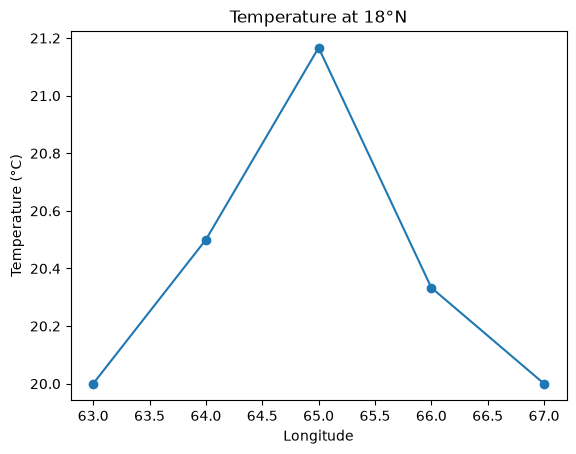

In [32]:
# starter code

fig = plt.figure()
ax = fig.add_subplot()

ax.plot(lon, temp_lat_lon[1], marker="o")

ax.set_xlabel("Longitude")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature at 18°N")

plt.show(fig)

Now let's annotate the plot with line indicating maximum temperature within range and the longitude at which it is attained

In [33]:
temp_lat18_lon = temp_lat_lon[1, :]

index = np.argmax(temp_lat18_lon)

max_temp = temp_lat18_lon[index]
lon_at_max = lon[index]

print("Maximum temp = ", max_temp, " , attained at lon = ", lon_at_max)

Maximum temp =  21.166666666666668  , attained at lon =  65.0


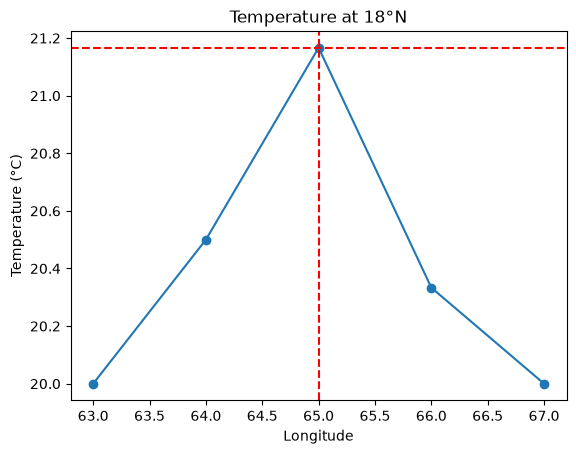

In [35]:
# starter code

fig = plt.figure()
ax = fig.add_subplot()

ax.plot(lon, temp_lat_lon[1], marker="o")

#### NEW
ax.axhline(max_temp, color="red", ls="--")
ax.axvline(lon_at_max, color="red", ls="--")
#### NEW

ax.set_xlabel("Longitude")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature at 18°N")

plt.show(fig)

Now let's plot data from both latitudes

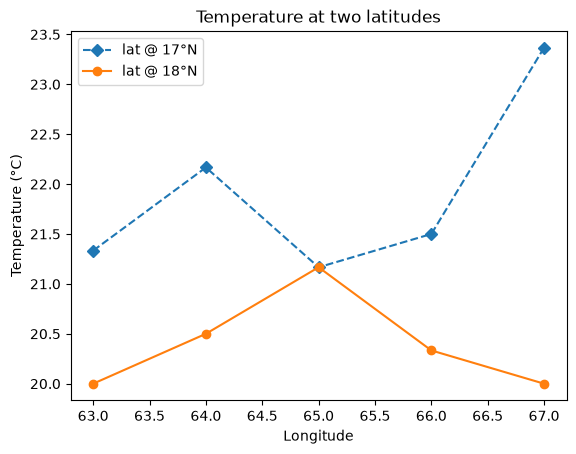

In [40]:
# starter code

fig = plt.figure()
ax = fig.add_subplot()

ax.plot(lon, temp_lat_lon[0], marker="D", ls="--", label="lat @ 17°N")
ax.plot(lon, temp_lat_lon[1], marker="o", label="lat @ 18°N")

ax.set_xlabel("Longitude")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature at two latitudes")

ax.legend()

plt.show(fig)

### Additional plot types

In [41]:
# Don't worry about the details of this code block

# Generate some random data

np.random.seed(42)
y1 = np.random.rand(100)
y2 = y1 + np.random.rand(100)

In [43]:
y1

array([0.37454012, 0.95071431, 0.73199394, 0.59865848, 0.15601864,
       0.15599452, 0.05808361, 0.86617615, 0.60111501, 0.70807258,
       0.02058449, 0.96990985, 0.83244264, 0.21233911, 0.18182497,
       0.18340451, 0.30424224, 0.52475643, 0.43194502, 0.29122914,
       0.61185289, 0.13949386, 0.29214465, 0.36636184, 0.45606998,
       0.78517596, 0.19967378, 0.51423444, 0.59241457, 0.04645041,
       0.60754485, 0.17052412, 0.06505159, 0.94888554, 0.96563203,
       0.80839735, 0.30461377, 0.09767211, 0.68423303, 0.44015249,
       0.12203823, 0.49517691, 0.03438852, 0.9093204 , 0.25877998,
       0.66252228, 0.31171108, 0.52006802, 0.54671028, 0.18485446,
       0.96958463, 0.77513282, 0.93949894, 0.89482735, 0.59789998,
       0.92187424, 0.0884925 , 0.19598286, 0.04522729, 0.32533033,
       0.38867729, 0.27134903, 0.82873751, 0.35675333, 0.28093451,
       0.54269608, 0.14092422, 0.80219698, 0.07455064, 0.98688694,
       0.77224477, 0.19871568, 0.00552212, 0.81546143, 0.70685

In [44]:
y2

array([0.4059693 , 1.58712472, 1.04634992, 1.10722918, 1.06358511,
       0.40528675, 0.46846654, 1.62172728, 0.82991318, 0.78505249,
       0.31033595, 1.13113114, 1.76214029, 1.02045949, 0.81522872,
       1.0548651 , 1.10791432, 0.71132649, 1.32450402, 0.83057138,
       1.41929305, 1.03558516, 0.61014812, 0.47641377, 0.68400515,
       1.21228375, 1.01768855, 1.37496502, 0.5993667 , 0.55719772,
       1.02495586, 0.39263193, 0.18491696, 1.28650071, 1.90854174,
       1.13160028, 0.82340439, 0.80069107, 1.04786263, 1.41193458,
       1.08448553, 0.74695921, 0.53163703, 1.21019871, 0.54362048,
       0.69940923, 0.92127541, 1.02274704, 0.59818903, 0.46350092,
       1.87785051, 1.01469471, 1.08439381, 1.38428011, 1.58355043,
       1.16392951, 0.76062805, 0.95760248, 0.28286483, 1.05354668,
       0.75646042, 0.90365486, 1.46226722, 0.89252801, 0.37122428,
       1.37799858, 0.46170429, 0.98871549, 0.11532579, 1.57777988,
       1.44980913, 0.21530351, 0.51761518, 1.0419572 , 1.35203

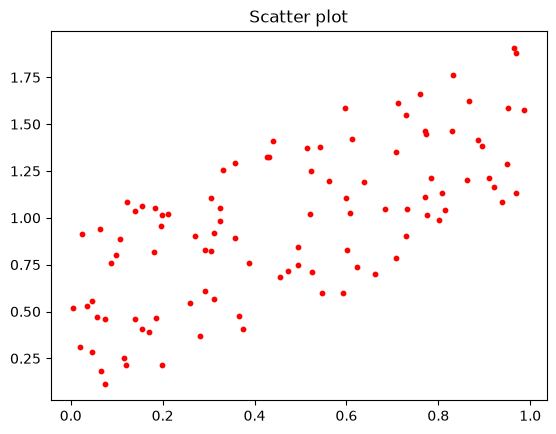

In [42]:
# scatter plot

fig = plt.figure() 
ax = fig.add_subplot()

ax.scatter(y1, y2, c = 'red', s = 10)
ax.set_title("Scatter plot")

plt.show(fig)

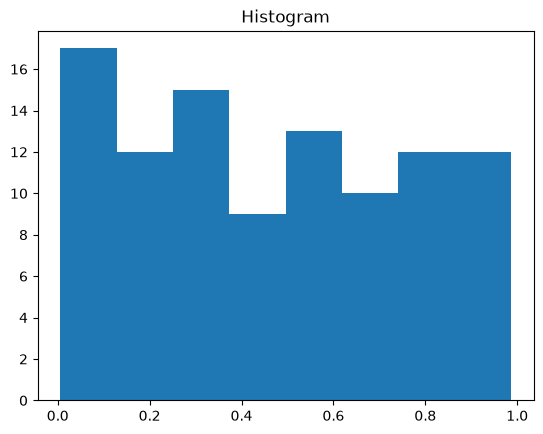

In [47]:
# histogram

fig = plt.figure()
ax = fig.add_subplot()

# change bins to see effect of bin size
ax.hist(y1, bins=8) 
ax.set_title("Histogram")

plt.show(fig)

In [48]:
# average rainfall data across different cities

labels = ['Seattle', 'San Diego', 'New York', 'Miami', 'St. Louis']
rain = [50, 30 , 40, 70, 45]

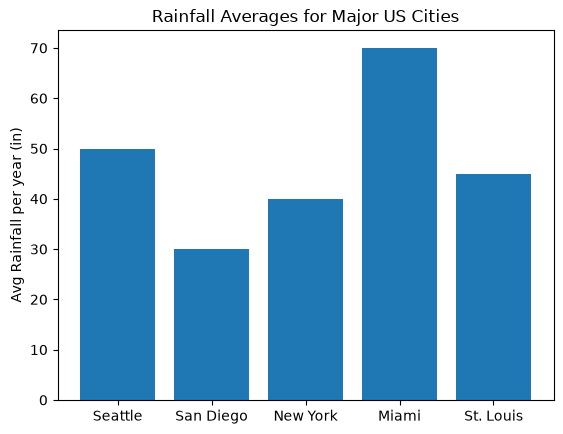

In [49]:
# bar plot

fig = plt.figure()
ax = fig.add_subplot()

ax.bar(labels, rain)

ax.set_ylabel('Avg Rainfall per year (in)')
ax.set_title('Rainfall Averages for Major US Cities')

plt.show(fig)

In [50]:
# San Francisco temperature data

months = np.arange(1, 13)

sf_temps = np.array([51, 54, 56, 57, 59, 61, 62, 62, 63, 62, 57, 51]) # Mean monthly temps of SF

sf_low = np.array([46, 49, 51, 53, 54, 55, 56, 57, 58, 56, 52, 47]) # Monthly Lows
sf_high = np.array([57, 60, 63, 65, 67, 69, 70, 70, 72, 70, 63, 57]) # Monthly Highs

sf_stdevs = np.array([2, 3, 4, 5, 6, 7, 8, 9, 11, 6, 3, 2])/4 # Monthly standard deviations

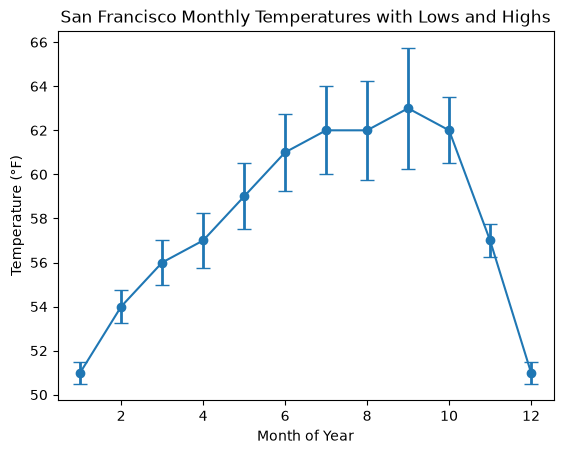

In [51]:
# error bar representing standard deviations in temperature

fig = plt.figure()
ax = fig.add_subplot()

ax.errorbar(months, sf_temps, yerr = sf_stdevs, capsize = 5, elinewidth = 2, marker = 'o')

ax.set_xlabel('Month of Year')
ax.set_ylabel('Temperature (°F)')
ax.set_title('San Francisco Monthly Temperatures with Lows and Highs')

plt.show(fig)

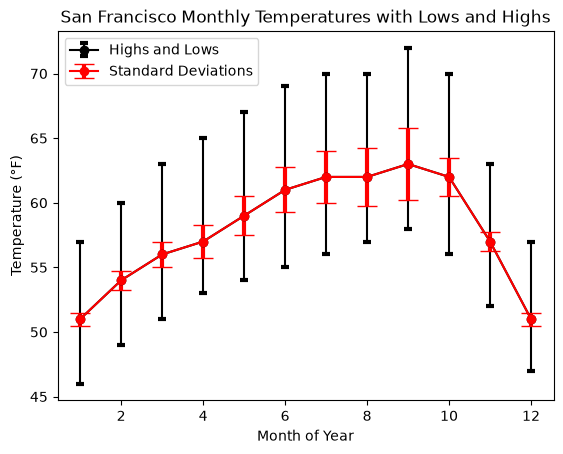

In [52]:
# more complicated example: thick errorbars for standard deviation, thin errorbars for range

temp_yerr = np.zeros((2, 12)) # Initialize 2x12 array to feed into errorbar
temp_yerr[0,:] = sf_temps - sf_low # Low limit
temp_yerr[1,:] = sf_high - sf_temps # High limit

fig = plt.figure()
ax = fig.add_subplot()

ax.errorbar(
    months, sf_temps, yerr = temp_yerr, 
    capsize = 3, capthick = 3, marker = 'o', color = 'k', 
    label = 'Highs and Lows'
)
ax.errorbar(
    months, sf_temps, yerr = sf_stdevs, 
    capsize = 7, elinewidth = 3, marker = 'o', color = 'r', 
    label = 'Standard Deviations'
)

ax.set_xlabel('Month of Year')
ax.set_ylabel('Temperature (°F)')
ax.set_title('San Francisco Monthly Temperatures with Lows and Highs')
ax.legend()

plt.show(fig)

<!-- BEGIN QUESTION -->

### Poll 6 (think-pair-share, JupyterHub **off**)

Consider the follow data on salinity across latitude and longitude
```python
sal_table = np.array([
    [45, -145, 34.2],
    [45.2, -145, 34.4],
    ...
    [47, -145, 35.6],
    [45, -144.8, 33.9],
    [45.2, -144.8, 33.9],
    ...
    [50, -140, 34.5]
])
```

If we want to plot the **distiribution** of salinity values across the geographical region, which matplotlib plotting function should we use?

<!-- END QUESTION -->

### Improving a plot

The following data is the number of dark count a fluorometer reports as a function of time. The goal of the measurement is to find the average dark count so that it can be subtracted from actual measurements

In [ ]:
# time in seconds
time = np.arange(0, 300, 5)
counts = np.array([
    42, 39, 43, 49, 38, 38, 49, 44, 37, 43, 
    37, 37, 41, 30, 30, 36, 33, 41, 34, 31, 
    48, 38, 40, 31, 36, 40, 33, 42, 36, 38, 
    36, 50, 39, 33, 44, 32, 41, 30, 32, 41, 
    44, 41, 39, 38, 31, 35, 37, 46, 42, 30, 
    41, 37, 35, 43, 46, 45, 34, 38, 41, 45
])

mean_counts = np.mean(counts)

Here is a plot illustrating the data

In [ ]:
# starter code

fig = plt.figure()
ax = fig.add_subplot()

ax.plot(time, counts, c="tab:blue")
ax.axhline(mean_counts, c="tab:blue")

plt.show(fig)

<!-- BEGIN QUESTION -->

### Poll 7 (think-pair-share)

Suggest ways to improve the plot above

<!-- END QUESTION -->

